# 01 — Data description and exploratory data analysis
**Competition:** [New York City Taxi Trip Duration](https://www.kaggle.com/competitions/nyc-taxi-trip-duration) (Kaggle, 2017)

**Task.** Predict how long a taxi trip in New York City will take (`trip_duration`, in seconds),
knowing only what is available when the trip starts: pickup time, pickup and dropoff coordinates,
number of passengers, vendor.

**Metric: RMSLE** (Root Mean Squared Logarithmic Error)

$$\varepsilon = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\big(\log(p_i+1) - \log(a_i+1)\big)^2}$$

In plain words: errors are measured on a log scale, so the metric rewards getting the **ratio** right,
not the absolute number of seconds. Predicting 10 min for a 5 min trip costs as much as predicting
2 h for a 1 h trip. Long trips therefore do not dominate the score, and under-prediction is penalised
slightly more than over-prediction of the same size.
Practical consequence: we train every model on `log1p(trip_duration)` with ordinary RMSE —
RMSE on the log scale **is** RMSLE on the original scale.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data import FIG_DIR, TARGET, anomaly_report, load_data
from src.features import datetime_features, distance_features

FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 140)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Data loading

In [2]:
train, test = load_data()
print(f"train: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"test:  {test.shape[0]:,} rows x {test.shape[1]} columns")
print("columns only in train:", sorted(set(train.columns) - set(test.columns)))
train.head()

train: 1,458,644 rows x 11 columns
test:  625,134 rows x 9 columns
columns only in train: ['dropoff_datetime', 'trip_duration']


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


## 2. Description of the features

In [3]:
meaning = {
    "id": "unique trip identifier",
    "vendor_id": "taxi company that recorded the trip (1 or 2)",
    "pickup_datetime": "date and time the meter was started",
    "dropoff_datetime": "date and time the meter was stopped (train only — it reveals the target, so it is NOT used as a feature)",
    "passenger_count": "number of passengers, entered by the driver",
    "pickup_longitude": "pickup longitude",
    "pickup_latitude": "pickup latitude",
    "dropoff_longitude": "dropoff longitude",
    "dropoff_latitude": "dropoff latitude",
    "store_and_fwd_flag": "Y = trip record held in the vehicle memory and sent later (no server connection)",
    "trip_duration": "TARGET: trip duration in seconds (train only)",
}
kind = {
    "id": "identifier", "vendor_id": "categorical (binary)", "pickup_datetime": "datetime",
    "dropoff_datetime": "datetime", "passenger_count": "discrete numeric / ordinal",
    "store_and_fwd_flag": "categorical (binary)", "trip_duration": "numeric (target)",
}
desc = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "feature type": [kind.get(c, "numeric (continuous)") for c in train.columns],
    "n_unique": train.nunique(),
    "missing": train.isna().sum(),
    "meaning": [meaning[c] for c in train.columns],
})
desc

,dtype,feature type,n_unique,missing,meaning
id,str,identifier,1458644,0,unique trip identifier
vendor_id,int64,categorical (binary),2,0,taxi company that recorded the trip (1 or 2)
pickup_datetime,datetime64[us],datetime,1380222,0,date and time the meter was started
dropoff_datetime,datetime64[us],datetime,1380377,0,date and time the meter was stopped (train onl...
passenger_count,int64,discrete numeric / ordinal,10,0,"number of passengers, entered by the driver"
pickup_longitude,float64,numeric (continuous),23047,0,pickup longitude
pickup_latitude,float64,numeric (continuous),45245,0,pickup latitude
dropoff_longitude,float64,numeric (continuous),33821,0,dropoff longitude
dropoff_latitude,float64,numeric (continuous),62519,0,dropoff latitude
store_and_fwd_flag,str,categorical (binary),2,0,Y = trip record held in the vehicle memory and...


In [4]:
train.describe().T.round(3)

,count,mean,min,25%,50%,75%,max,std
vendor_id,1458644.0,1.53495,1.0,1.0,2.0,2.0,2.0,0.498777
pickup_datetime,1458644,2016-04-01 10:10:24.940038,2016-01-01 00:00:17,2016-02-17 16:46:04.250000,2016-04-01 17:19:40,2016-05-15 03:56:08.750000,2016-06-30 23:59:39,NaN
dropoff_datetime,1458644,2016-04-01 10:26:24.432309,2016-01-01 00:03:31,2016-02-17 17:05:32.500000,2016-04-01 17:35:12,2016-05-15 04:10:51.750000,2016-07-01 23:02:03,NaN
passenger_count,1458644.0,1.66453,0.0,1.0,1.0,2.0,9.0,1.314242
pickup_longitude,1458644.0,-73.973486,-121.933342,-73.991867,-73.981743,-73.967331,-61.335529,0.070902
pickup_latitude,1458644.0,40.750921,34.359695,40.737347,40.754101,40.76836,51.881084,0.032881
dropoff_longitude,1458644.0,-73.973416,-121.933304,-73.991325,-73.979752,-73.963013,-61.335529,0.070643
dropoff_latitude,1458644.0,40.7518,32.181141,40.735885,40.754524,40.76981,43.921028,0.035891
trip_duration,1458644.0,959.492273,1.0,397.0,662.0,1075.0,3526282.0,5237.431724


In [5]:
print("train period:", train.pickup_datetime.min(), "->", train.pickup_datetime.max())
print("test period: ", test.pickup_datetime.min(), "->", test.pickup_datetime.max())

train period: 2016-01-01 00:00:17 -> 2016-06-30 23:59:39
test period:  2016-01-01 00:00:22 -> 2016-06-30 23:59:58


Train and test cover the **same six months (Jan–Jun 2016)**: Kaggle split the trips randomly,
not by time. A random hold-out split is therefore a faithful imitation of the test set (used in notebook 02).

## 3. Target distribution

count    1458644.0
mean         959.5
std         5237.4
min            1.0
25%          397.0
50%          662.0
75%         1075.0
max      3526282.0
Name: trip_duration, dtype: float64


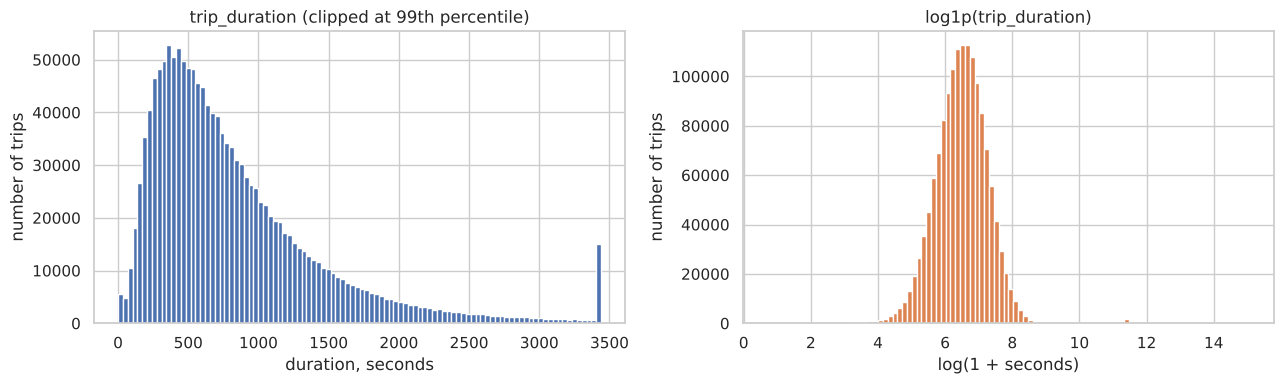

In [6]:
y = train[TARGET]
print(y.describe().round(1))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(y.clip(upper=y.quantile(0.99)), bins=100, color="#4C72B0")
axes[0].set(title="trip_duration (clipped at 99th percentile)", xlabel="duration, seconds", ylabel="number of trips")
axes[1].hist(np.log1p(y), bins=100, color="#DD8452")
axes[1].set(title="log1p(trip_duration)", xlabel="log(1 + seconds)", ylabel="number of trips")
save(fig, "01_target_distribution")
plt.show()

**Findings.**
* The raw target is extremely right-skewed: median ≈ 11 min, mean ≈ 16 min, but the maximum is ~41 days.
* After `log1p` the distribution is close to normal (peak around e^6.5 ≈ 11 min).
  This confirms training on the log scale, which is exactly what RMSLE measures.
* There is a small bump of very short trips (left tail) and a cluster of ~86 400 s (24 h) trips —
  meters that were never stopped. These are examined in section 6.

## 4. Distributions of the main features

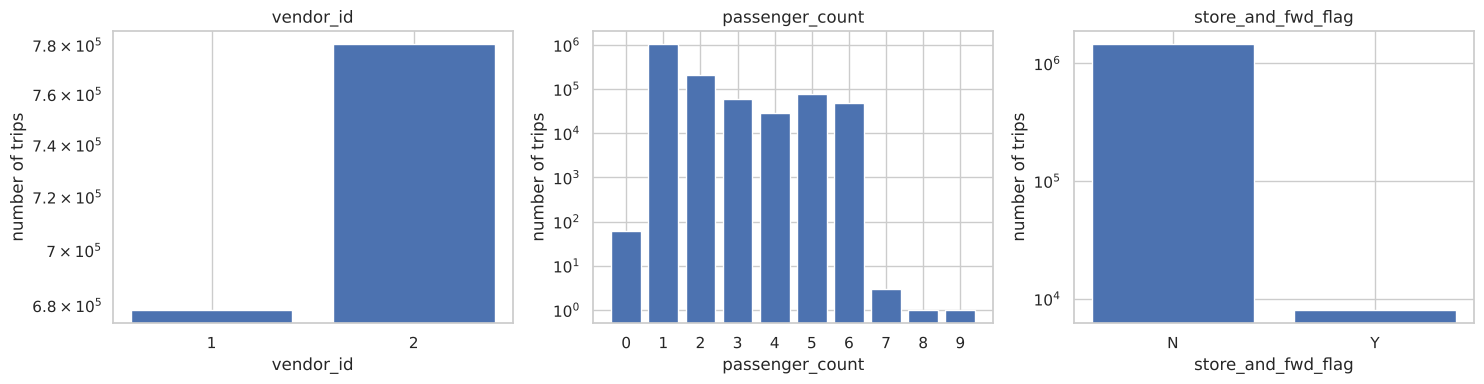

vendor_id {1: 46.5, 2: 53.5}
passenger_count {0: 0.0, 1: 70.86, 2: 14.42, 3: 4.11, 4: 1.95, 5: 5.35, 6: 3.31, 7: 0.0, 8: 0.0, 9: 0.0}
store_and_fwd_flag {'N': 99.45, 'Y': 0.55}


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["vendor_id", "passenger_count", "store_and_fwd_flag"]):
    vc = train[col].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color="#4C72B0")
    ax.set(title=col, xlabel=col, ylabel="number of trips")
    ax.set_yscale("log")
save(fig, "01_categorical_features")
plt.show()
for col in ["vendor_id", "passenger_count", "store_and_fwd_flag"]:
    print(col, (train[col].value_counts(normalize=True).sort_index() * 100).round(2).to_dict())

**Findings** (y axis is logarithmic):
* `vendor_id`: two vendors, fairly balanced (vendor 2 ≈ 53%).
* `passenger_count`: 71% of trips have one passenger; 0 and 7–9 passengers are rare and
  most likely data-entry errors (60 trips with 0 passengers).
* `store_and_fwd_flag`: very imbalanced — only 0.55% "Y".

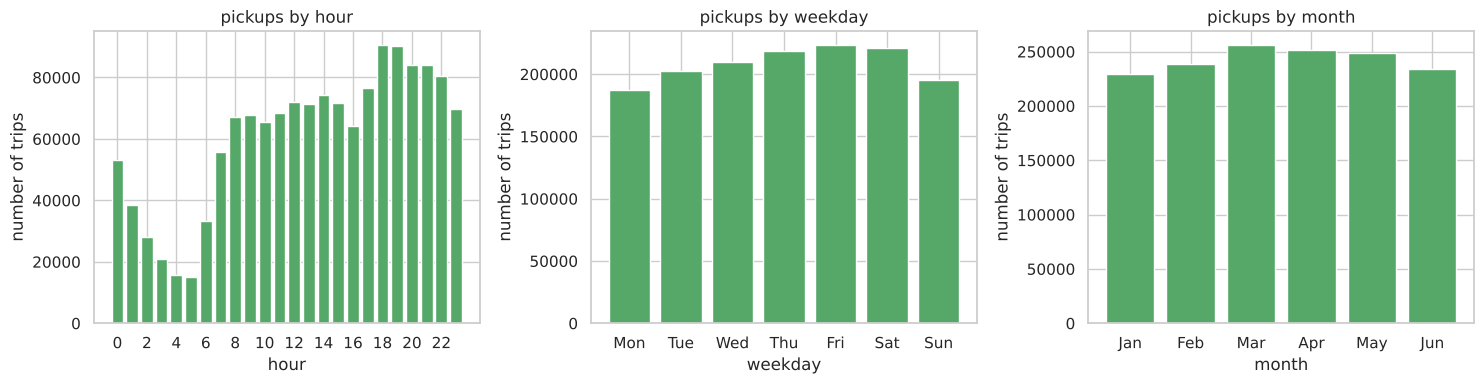

In [8]:
dt = datetime_features(train)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, labels in zip(axes, ["hour", "weekday", "month"],
                           [None, ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]]):
    vc = dt[col].value_counts().sort_index()
    ax.bar(labels if labels else vc.index.astype(str), vc.values, color="#55A868")
    ax.set(title=f"pickups by {col}", xlabel=col, ylabel="number of trips")
axes[0].set_xticks(range(0, 24, 2))
save(fig, "01_datetime_features")
plt.show()

**Findings.** Demand is lowest around 5 am and peaks at 6–7 pm; Friday and Saturday are the busiest days,
Monday the quietest; months are roughly equal (January lowest, March highest). The daily series below shows
a sharp drop on 23–24 January 2016 (the blizzard), and train and test follow the same pattern day by day.

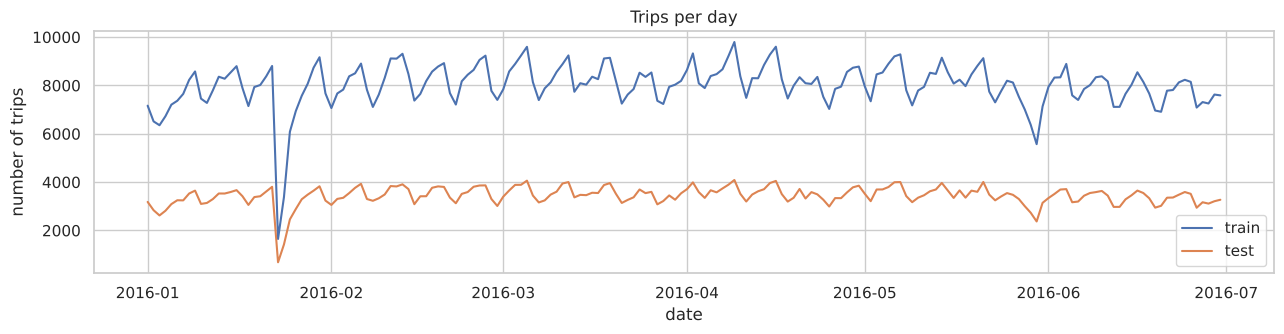

In [9]:
fig, ax = plt.subplots(figsize=(13, 3.5))
daily = train.set_index("pickup_datetime").resample("D").size()
daily_test = test.set_index("pickup_datetime").resample("D").size()
ax.plot(daily.index, daily.values, label="train")
ax.plot(daily_test.index, daily_test.values, label="test")
ax.set(title="Trips per day", xlabel="date", ylabel="number of trips")
ax.legend()
save(fig, "01_trips_per_day")
plt.show()

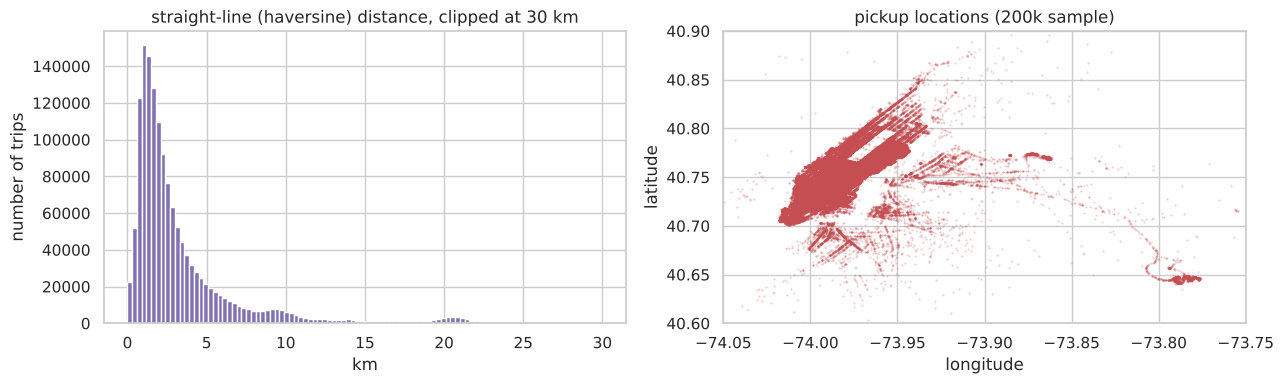

count    1458644.00
mean           3.44
std            4.30
min            0.00
25%            1.23
50%            2.09
75%            3.88
max         1240.91
Name: dist_haversine, dtype: float64


In [10]:
dist = distance_features(train)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(dist["dist_haversine"].clip(upper=30), bins=100, color="#8172B2")
axes[0].set(title="straight-line (haversine) distance, clipped at 30 km", xlabel="km", ylabel="number of trips")
sample = train.sample(200_000, random_state=0)
axes[1].scatter(sample.pickup_longitude, sample.pickup_latitude, s=0.2, alpha=0.3, color="#C44E52")
axes[1].set(xlim=(-74.05, -73.75), ylim=(40.60, 40.90), title="pickup locations (200k sample)",
            xlabel="longitude", ylabel="latitude")
save(fig, "01_distance_and_map")
plt.show()
print(dist["dist_haversine"].describe().round(2))

**Findings.** The coordinates draw a map of New York: most pickups are in Manhattan, with two dense spots
far to the east — LaGuardia (≈ -73.87, 40.77) and JFK (≈ -73.78, 40.64) airports. The median trip is
~2 km in a straight line; airport trips create a long right tail.
The raw coordinates alone do not give the model the distance — it has to be engineered (notebook 03).

## 5. Relations between the main features and the target

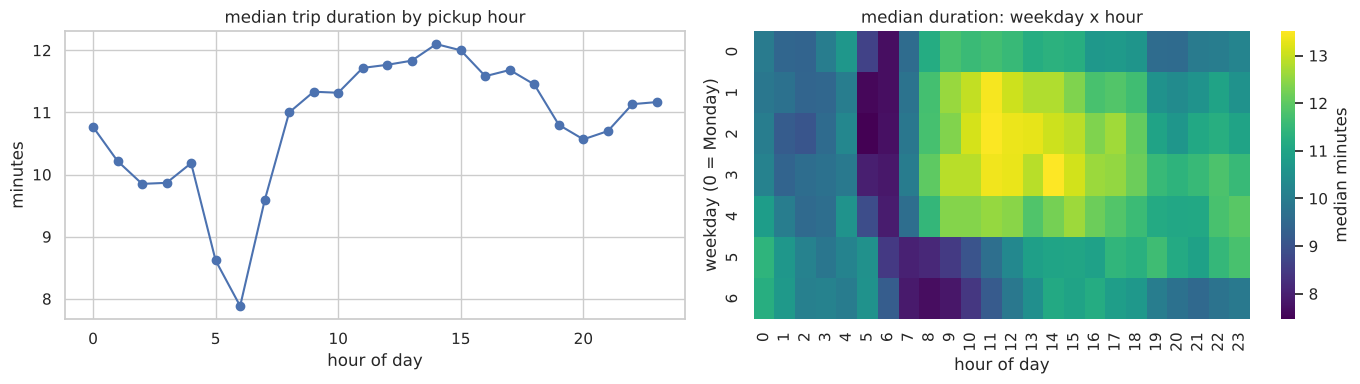

In [11]:
train["log_duration"] = np.log1p(train[TARGET])
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
med_h = train.groupby(dt["hour"])[TARGET].median() / 60
axes[0].plot(med_h.index, med_h.values, marker="o")
axes[0].set(title="median trip duration by pickup hour", xlabel="hour of day", ylabel="minutes")
pivot = train.groupby([dt["weekday"], dt["hour"]])[TARGET].median().unstack() / 60
sns.heatmap(pivot, ax=axes[1], cmap="viridis", cbar_kws={"label": "median minutes"})
axes[1].set(title="median duration: weekday x hour", xlabel="hour of day", ylabel="weekday (0 = Monday)")
save(fig, "01_duration_by_time")
plt.show()

**Findings.** Time of day matters a lot: the median trip takes ~8 min at 6 am and ~12 min at 2–3 pm
(traffic); on Tue–Thu late mornings it reaches ~13 min. On weekends the morning is the fastest time
(~8 min at 8 am on Sunday), while trips after midnight are longer than on weekdays (nightlife). Hour × weekday is a strong interaction — tree models will capture it.

Spearman corr(distance, duration): 0.794


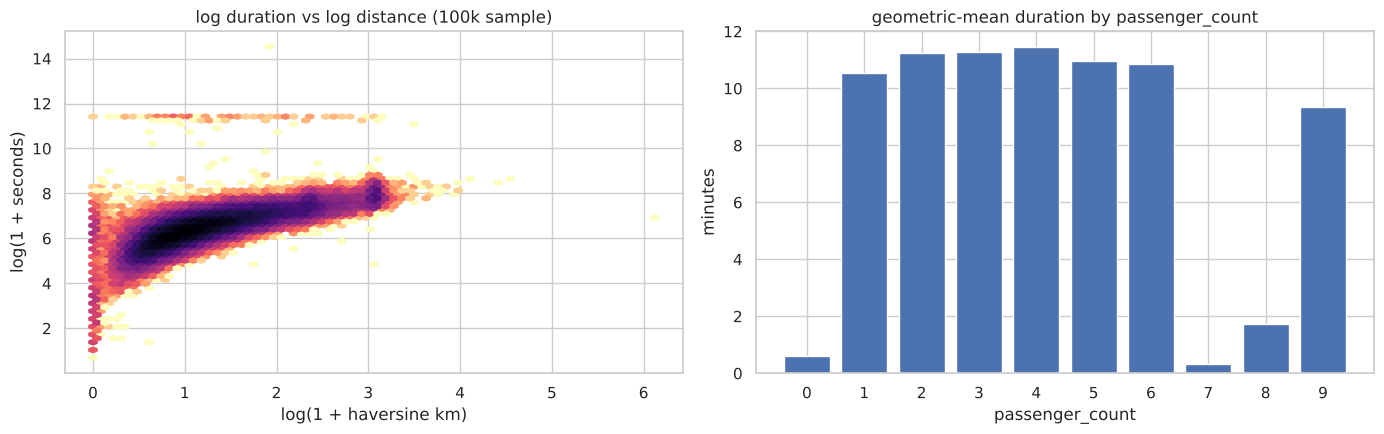

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
s = train.sample(100_000, random_state=1)
s_dist = distance_features(s)["dist_haversine"]
axes[0].hexbin(np.log1p(s_dist), s["log_duration"], gridsize=70, bins="log", cmap="magma_r")
axes[0].set(title="log duration vs log distance (100k sample)",
            xlabel="log(1 + haversine km)", ylabel="log(1 + seconds)")
print("Spearman corr(distance, duration):", round(dist["dist_haversine"].corr(train[TARGET], method="spearman"), 3))

grp = train.groupby("passenger_count")["log_duration"].agg(["mean", "count"])
axes[1].bar(grp.index.astype(str), np.expm1(grp["mean"]) / 60, color="#4C72B0")
axes[1].set(title="geometric-mean duration by passenger_count", xlabel="passenger_count", ylabel="minutes")
save(fig, "01_duration_vs_distance_passengers")
plt.show()

In [13]:
pd.DataFrame({
    "vendor: geo-mean minutes": np.expm1(train.groupby("vendor_id")["log_duration"].mean()) / 60,
}).round(2), pd.DataFrame({
    "store_and_fwd: geo-mean minutes": np.expm1(train.groupby("store_and_fwd_flag")["log_duration"].mean()) / 60,
}).round(2)

(           vendor: geo-mean minutes
 vendor_id                          
 1                             10.53
 2                             10.87,
                     store_and_fwd: geo-mean minutes
 store_and_fwd_flag                                 
 N                                             10.70
 Y                                             12.62)

**Findings.**
* **Distance is by far the strongest predictor** (Spearman ρ ≈ 0.79): on the log–log scale the
  relation is almost linear. Points at high distance with tiny duration are errors.
* `passenger_count` between 1 and 6 has only a weak effect (10.5–11.5 min). Trips with 0 or 7 passengers
  last under a minute on average — another sign that these records are errors or cancelled rides.
* Vendors differ little in typical duration (10.5 vs 10.9 min), but vendor 2 records 2 053 of the 2 061
  trips longer than 6 h (see below). `store_and_fwd = Y` trips are longer (12.6 vs 10.7 min).

## 6. Missing values and anomalies

In [14]:
print("missing values in train:", int(train.isna().sum().sum()), "| in test:", int(test.isna().sum().sum()))
print("dropoff - pickup == trip_duration for every row:",
      bool(((train.dropoff_datetime - train.pickup_datetime).dt.total_seconds() == train[TARGET]).all()))
pd.concat({"train": anomaly_report(train), "test": anomaly_report(test)}, axis=1)

missing values in train: 0 | in test: 0
dropoff - pickup == trip_duration for every row: True


train            test        
                                  count share_%   count share_%
pickup or dropoff outside NYC box   998   0.068   399.0   0.064
passenger_count == 0                 60   0.004    23.0   0.004
passenger_count > 6                   5   0.000     2.0   0.000
pickup == dropoff coordinates      5897   0.404  2475.0   0.396
trip_duration > 6 h                2061   0.141     NaN     NaN
trip_duration < 60 s               8595   0.589     NaN     NaN

In [15]:
long = train[train[TARGET] > 6 * 3600]
print("trips > 6 h by vendor:", long.vendor_id.value_counts().to_dict())
print("median distance of trips > 6 h:", round(distance_features(long)["dist_haversine"].median(), 2), "km")
speed = dist["dist_haversine"] / (train[TARGET] / 3600)
print("trips with straight-line speed > 100 km/h:", int((speed > 100).sum()))

trips > 6 h by vendor: {2: 2053, 1: 8}
median distance of trips > 6 h: 2.4 km
trips with straight-line speed > 100 km/h: 175


**Findings / data problems.**
* **No missing values** in either file; `dropoff_datetime` is perfectly consistent with the target
  (and must be dropped because it is a leak — it does not exist in test).
* **Extreme durations:** 2 061 trips > 6 h (mostly ≈ 24 h, 2 053 of them vendor 2, median distance only 2.4 km) —
  meters that were not switched off; a handful last for weeks (max ≈ 41 days).
* **Very short trips:** 8 595 trips < 60 s; 5 897 trips have identical pickup and dropoff coordinates
  (cancelled rides or GPS failures). Both kinds also exist in test (0.4% zero-distance trips).
* **Impossible speeds:** 175 trips imply > 100 km/h in a straight line.
* **Passenger count** 0 (60 trips) or 7–9 (5 trips).
* **Coordinates** outside NYC (~1 000 trips, some in the ocean or other states).

How they are handled (drop / keep / flag) and why is decided and tested in notebook 02.

## 7. Summary of the EDA
1. The target is log-normal-like → model `log1p(duration)`; this also optimises RMSLE directly.
2. Trip distance is the dominant signal but is not a raw feature → engineer distances.
3. Time of day × day of week has a strong, non-linear effect (traffic) → datetime features + tree models.
4. Location matters beyond distance (airports, Manhattan grid) → coordinate clusters / rotated coordinates.
5. A small number of clearly wrong records (≈ 0.2%) exists in train; the test set has the same kinds of errors,
   so the validation part must keep them to estimate the leaderboard score honestly.